In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# WEEK 2

In [3]:
df = pd.read_csv("sets.csv", sep=',')
print(df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())

(14936, 17)
  Set_ID            Name  Year      Theme Theme_Group   Subtheme Category  \
0   75-1   PreSchool Set  1975  PreSchool  Pre-school        NaN   Normal   
1   77-1   PreSchool Set  1975  PreSchool  Pre-school        NaN   Normal   
2  077-1  Pre-School Set  1975      Duplo  Pre-school        NaN   Normal   
3   78-1   PreSchool Set  1975  PreSchool  Pre-school        NaN   Normal   
4   78-3       Basic Set  1975  Samsonite     Vintage  Basic set   Normal   

         Packaging  Num_Instructions     Availability  Pieces  Minifigures  \
0  {Not specified}                 0  {Not specified}    16.0          NaN   
1  {Not specified}                 0  {Not specified}    20.0          NaN   
2  {Not specified}                 0  {Not specified}    21.0          NaN   
3  {Not specified}                 0  {Not specified}    32.0          NaN   
4              Box                 0  {Not specified}   330.0          NaN   

   Owned  Rating  USD_MSRP  Total_Quantity  Current_Pric

As can be seen above, our dataset consists of 17 columns: 7 floats, 8 strings, and 2 integers and 14936 rows.  
Then, there are numerous columns that contain null values, notably USD-MSRP and Current_price.  
We will therefore need to remove a large portion of the dataset during the cleaning phase; since our goal is to predict the price, it would be too risky to keep these columns or to artificially generate the prices.


In [4]:
df.notna().all(axis=1).sum()

np.int64(2222)

We discovered that there are only 2222 rows containing all the information, so we need to select columns.

## Clean the data

In [5]:
print(f"Number of duplicates : {df.duplicated().sum()}")

Number of duplicates : 0


In [6]:
colonnes = [
    "Year",
    "Theme",
    "Theme_Group",
    "Subtheme",
    "Category",
    "Packaging",
    "Num_Instructions",
    "Availability",
    "Pieces",
    "Minifigures",
    "Owned",
    "Rating",
    "USD_MSRP",
    "Total_Quantity",
    "Current_Price"
]

numeric_cols = [
    "Year",
    "Num_Instructions",
    "Pieces",
    "Minifigures",
    "Owned",
    "Rating",
    "USD_MSRP",
    "Total_Quantity",
    "Current_Price"
]

categorical_cols = [
    "Theme",
    "Theme_Group",
    "Subtheme",
    "Category",
    "Packaging",
    "Availability"
]

First, we need to remove the Set_ID and Name columns to prevent the model from memorizing the sets.

In [7]:
df_clean = df.drop(["Set_ID", "Name"], axis=1)

Before dropping the rows with null values, let's see if we can impute the missing values. To do this, we'll look at the percentage of non-null values to see if it's large enough to extrapolate.

In [8]:
for col in colonnes:
    print("Percentage of non null values in column ", col, ": ", 100-(df[col].isnull().sum() / df.shape[0] * 100), '%')

Percentage of non null values in column  Year :  100.0 %
Percentage of non null values in column  Theme :  100.0 %
Percentage of non null values in column  Theme_Group :  99.85940010712373 %
Percentage of non null values in column  Subtheme :  76.9617032672737 %
Percentage of non null values in column  Category :  100.0 %
Percentage of non null values in column  Packaging :  100.0 %
Percentage of non null values in column  Num_Instructions :  100.0 %
Percentage of non null values in column  Availability :  100.0 %
Percentage of non null values in column  Pieces :  87.92849491162292 %
Percentage of non null values in column  Minifigures :  51.459560792715585 %
Percentage of non null values in column  Owned :  98.89528655597215 %
Percentage of non null values in column  Rating :  100.0 %
Percentage of non null values in column  USD_MSRP :  39.08007498660954 %
Percentage of non null values in column  Total_Quantity :  82.1906802356722 %
Percentage of non null values in column  Current_Pri

As you can see, the "subtheme", "theme_group", "Pieces", "Total_Quantity "and ‘owned’ columns can be replaced with imputation.   

Since USD_MSRP is our target variable, we cannot use imputation to replace missing prices. A supervised learning model needs real target values during training.

As for Minifigures and Current_Price, at the moment it seems to us that there isn't enough information to be able to use it.

We therefore decided to remove the rows where USD_MSRP is missing. This reduces our dataset from 14,936 to 5,837 observations.

For the remaining features, we can use imputation methods to preserve as much information as possible.

In [9]:
df_clean = df_clean.drop(["Minifigures","Current_Price"], axis=1).dropna(subset=["USD_MSRP"]).copy()
print(df_clean.shape)

(5837, 13)


In [10]:
df_clean[["Num_Instructions","Year"]] = df_clean[["Num_Instructions","Year"]].astype(float)

In [11]:
df_clean.head(10)

,Year,Theme,Theme_Group,Subtheme,Category,Packaging,Num_Instructions,Availability,Pieces,Owned,Rating,USD_MSRP,Total_Quantity
1706,1991.0,Trains,Modern day,9V,Normal,Box,0.0,Retail,8.0,3024.0,4.0,12.99,19.0
1707,1991.0,Trains,Modern day,9V,Normal,Box,0.0,Retail,8.0,2934.0,3.8,12.99,3.0
1708,1991.0,Trains,Modern day,9V,Normal,Box,0.0,Retail,6.0,3047.0,4.0,27.99,5.0
1713,1991.0,Trains,Modern day,9V,Normal,Box,0.0,Retail,3.0,2162.0,3.7,41.99,2.0
1831,1992.0,Duplo,Pre-school,NaN,Normal,{Not specified},0.0,{Not specified},1.0,1599.0,3.5,14.99,3.0
1957,1993.0,Duplo,Pre-school,Trains,Normal,{Not specified},0.0,{Not specified},6.0,470.0,0.0,4.99,0.0
1958,1993.0,Duplo,Pre-school,Trains,Normal,{Not specified},0.0,{Not specified},6.0,449.0,0.0,4.99,0.0
2397,1996.0,Basic,Basic,Supplementaries,Normal,Other,0.0,Retail,1.0,3636.0,4.1,4.99,10.0
2399,1996.0,Basic,Basic,Supplementaries,Normal,Shrink-wrapped,0.0,Retail,1.0,3964.0,4.0,14.99,2.0
2401,1996.0,Basic,Basic,Supplementaries,Normal,Polybag,0.0,Retail,1.0,2137.0,4.4,2.49,0.0


We need to check whether there are any categories in the category column that indicate we don't have any information-such as the {Not specified} category under “Packaging.”

In [12]:
for col in categorical_cols:
    print(col, " :\n", df_clean[col].unique(), "\n\n")

Theme  :
 <StringArray>
[                  'Trains',                    'Duplo',
                    'Basic',                    'Dacta',
                     'Town',              'Bulk Bricks',
                     'Gear',                'Star Wars',
                 'Seasonal',                 'Belville',
 ...
           'Brick Sketches', 'Minions: The Rise of Gru',
               'Monkie Kid',                   'Vidiyo',
  'Collectable minifigures',                   'Avatar',
        'Gabby's Dollhouse',                    'DUPLO',
                 'Dreamzzz',       'Sonic the Hedgehog']
Length: 109, dtype: str 


Theme_Group  :
 <StringArray>
[      'Modern day',       'Pre-school',            'Basic',
      'Educational',    'Miscellaneous',         'Licensed',
            'Girls',        'Technical',           'Racing',
     'Constraction',       'Historical',     'Model making',
 'Action/Adventure',           'Junior',   'Art and crafts',
                nan]
Length: 16, dtype:

Upon closer inspection, we see that the only column posing a problem is the one labeled {Not specified} under the “Packaging” heading, but we decided to keep it because the absence of information is, after all, a form of information. It is, in fact, an adjustment variable that we must take into account. In fact, this variable gave us the idea to fill in the null values for Subtheme and Theme_Group with a similar category.

In [13]:
df_clean["Subtheme"] = df_clean["Subtheme"].fillna("Not specified")
df_clean["Theme_Group"] = df_clean["Theme_Group"].fillna("Not specified")

In [14]:
df_clean.to_csv("lego_cleaned.csv", index=False)

print("Dataset exported successfully!")
print("Shape:", df_clean.shape)

Dataset exported successfully!
Shape: (5837, 13)


## Outliers

In [15]:
def detect_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1

    mask = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    outliers = df_clean.loc[s.index[mask]]

    print(f"Number of outliers : {len(outliers)}")
    print(outliers[[s.name]].head())

for col in numeric_cols:
    if col in df_clean.columns:
        print(f"Outliers for {col}:")
        detect_outliers(df_clean[col])
        print("\n")

Outliers for Year:
Number of outliers : 11
        Year
1706  1991.0
1707  1991.0
1708  1991.0
1713  1991.0
1831  1992.0


Outliers for Num_Instructions:
Number of outliers : 156
      Num_Instructions
5828              10.0
7093              10.0
7607              13.0
7683              15.0
7945               9.0


Outliers for Pieces:
Number of outliers : 385
      Pieces
4769  3096.0
5973  3441.0
5974  1669.0
6167  1367.0
6233  1071.0


Outliers for Owned:
Number of outliers : 345
        Owned
5826  13782.0
5827  10671.0
5830  13471.0
6161  12210.0
6168  11955.0


Outliers for Rating:
Number of outliers : 0
Empty DataFrame
Columns: [Rating]
Index: []


Outliers for USD_MSRP:
Number of outliers : 363
      USD_MSRP
4769    269.99
5324    249.99
5973    269.99
5974    139.99
6256    149.99


Outliers for Total_Quantity:
Number of outliers : 460
      Total_Quantity
1706            19.0
6344            50.0
6655            23.0
7113            24.0
7179            20.0




We observe that only the “Rating” column has no outliers when using the IQR method.
however, the IQR method identifies several outliers in our numerical variables.

However, these values are not necessarily errors. For example, some LEGO sets can have much higher prices than others, and some themes may be much older than the majority of the dataset.

The same applies to Owned, Pieces and Num_Instructions, where unusually high values may represent real differences between LEGO sets.

We therefore decided not to remove these observations automatically. Removing them could result in losing useful information about expensive or unusual sets.

The IQR method is only used here to identify suspicious values, not to automatically classify them as incorrect.

### Target distribution

count    5837.000000
mean       39.967050
std        55.006213
min         1.490000
25%         9.990000
50%        19.990000
75%        49.990000
max       849.990000
Name: USD_MSRP, dtype: float64
Skewness: 4.668611637790357


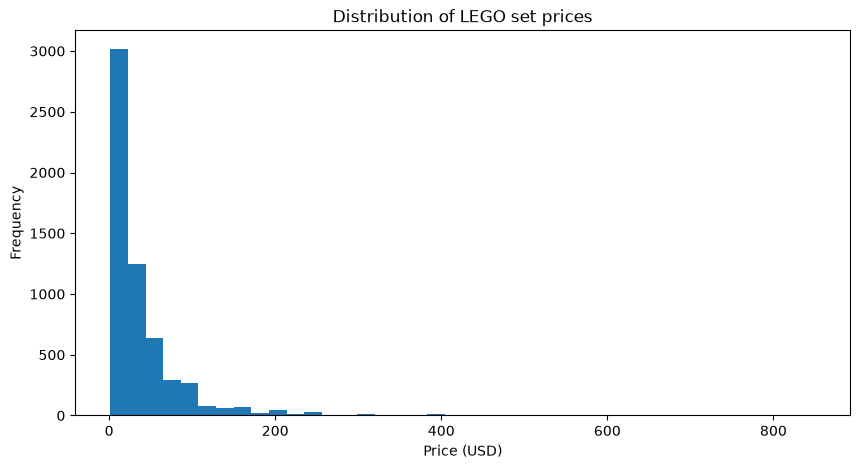

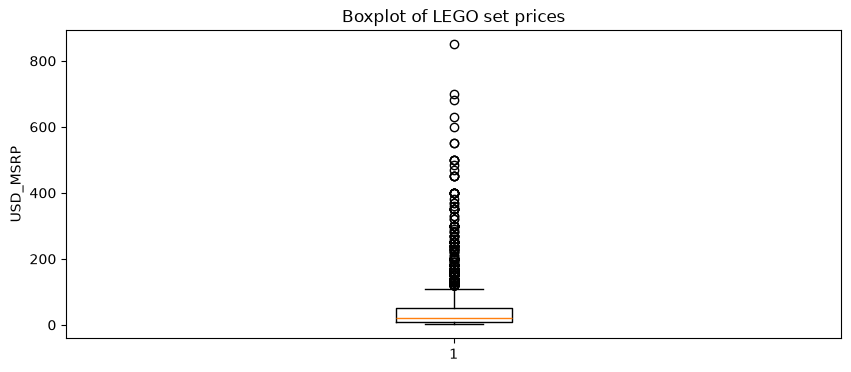

In [16]:
print(df_clean["USD_MSRP"].describe())

print("Skewness:", df_clean["USD_MSRP"].skew())

plt.figure(figsize=(10, 5))
plt.hist(df_clean["USD_MSRP"], bins=40)
plt.xlabel("Price (USD)")
plt.ylabel("Frequency")
plt.title("Distribution of LEGO set prices")
plt.show()

plt.figure(figsize=(10, 4))
plt.boxplot(df_clean["USD_MSRP"])
plt.title("Boxplot of LEGO set prices")
plt.ylabel("USD_MSRP")
plt.show()

As we can see from the histogram and the boxplot, the distribution of USD_MSRP is strongly right-skewed.

The skewness value is 4.67, which confirms that most LEGO sets have relatively low prices, while a smaller number of sets have much higher prices.

The mean price is $39.97, whereas the median is only $19.99. This difference shows that expensive sets have a strong influence on the average price.

We can also observe that 75% of the sets have a price below $49.99, while the maximum price reaches $849.99. These high prices explain the presence of numerous outliers in the boxplot.

We decided not to remove these expensive observations automatically because they may represent real LEGO sets. Removing them could cause us to lose important information.

However, this strong asymmetry may make price prediction more difficult, especially for expensive sets. We could therefore test a logarithmic transformation of USD_MSRP in a future experiment to reduce the influence of extreme values.

### Correlation analysis

In [17]:
print(
    df_clean[
        [col for col in numeric_cols if col in df_clean.columns]
    ].corr()["USD_MSRP"].sort_values(ascending=False)
)

USD_MSRP            1.000000
Pieces              0.876665
Num_Instructions    0.479166
Year                0.169822
Owned               0.168189
Rating              0.163077
Total_Quantity      0.005127
Name: USD_MSRP, dtype: float64


We can observe that Pieces has the strongest positive correlation with USD_MSRP (0.88). This suggests that LEGO sets with more pieces tend to have higher prices.

Num_instructions has moderate correlation (0.48), so this also seems important.

Year, Owned and Rating have weaker positive correlations, all around 0.16.

These results suggest that Num_Instructions may be an important feature for predicting the price. However, correlation only measures linear relationships and does not necessarily imply causation.

### Categorical feature analysis

In [18]:
for col in categorical_cols:

    print("\n", col)

    display(
        df_clean.groupby(col)['USD_MSRP']
        .agg(['count', 'median', 'mean'])
        .sort_values('count', ascending=False)
        .head(10)
    )


 Theme


,count,median,mean
Theme,,,
Gear,571,9.99,15.612627
City,527,29.99,41.964364
Star Wars,454,39.99,64.093546
Duplo,450,24.99,30.532222
Friends,348,19.99,31.228506
Ninjago,286,24.99,39.448042
Creator,224,19.99,29.190982
Technic,202,49.99,87.900891
Collectable Minifigures,129,2.99,4.298527



 Theme_Group


,count,median,mean
Theme_Group,,,
Licensed,1403,29.99,50.749095
Miscellaneous,1079,9.99,18.936033
Modern day,887,29.99,37.465186
Action/Adventure,639,24.99,37.755258
Pre-school,455,24.99,30.572418
Model making,378,39.99,72.632910
Technical,264,49.99,80.586856
Constraction,218,12.99,16.384541
Basic,139,14.99,21.241799



 Subtheme


,count,median,mean
Subtheme,,,
Not specified,895,29.99,45.432279
3 in 1,199,19.99,30.934824
Seasonal,83,29.99,23.827349
Licensed,82,109.99,137.709512
Minifig-scale,78,39.99,49.220769
Miscellaneous,72,24.99,66.642778
The Clone Wars,64,34.99,44.755625
Police,62,39.99,39.723871
Heartlake City,56,39.99,51.740000


... (2 outputs left out)


 Packaging


,count,median,mean
Packaging,,,
Box,4181,29.99,48.729321
{Not specified},901,14.99,23.506848
Foil pack,278,4.99,5.317338
Polybag,120,4.99,6.240000
Blister pack,82,14.99,13.355854
Tag,52,4.99,5.566923
Plastic canister,46,7.99,7.185652
Box with backing card,31,9.99,11.215806
Plastic box,30,19.99,25.090000



 Availability


,count,median,mean
Availability,,,
Retail,3891,24.99,36.106430
{Not specified},1098,14.99,26.176485
LEGO exclusive,557,14.99,78.157648
Retail - limited,273,39.99,65.870403
Educational,12,217.45,208.700000
Promotional,4,4.49,4.490000
Not sold,1,12.99,12.990000
Unknown,1,3.99,3.990000


We also analyzed the relationship between categorical variables and LEGO set prices by comparing the number of observations, median and mean prices for each category.

We can observe significant differences between themes. For example, Technic and Star Wars sets tend to have higher prices, while Collectable Minifigures and Gear sets are generally cheaper.

The same differences can be observed in Theme_Group and Subtheme. Licensed sets and Technical sets have relatively high average prices, whereas Miscellaneous and Constraction sets tend to be cheaper.

Regarding Packaging, sets sold in boxes have a higher average price than those sold in foil packs or polybags.

We also notice that some categories contain very few observations, such as Book and Random in the Category column. Their average prices should therefore be interpreted carefully.

These results suggest that categorical features contain useful information for predicting LEGO set prices. We will therefore keep these variables and use OneHotEncoder to transform them into numerical features.

## Preprocessing

Now we need to separate the data into X and Y. We'll use USD_MSRP as our target value.

In [19]:
X = df_clean.drop(columns=["USD_MSRP"])
y = df_clean["USD_MSRP"]

We decided to split our dataset into three different sets.

The training set (70%) is used to train the model. The validation set (15%) is used to compare models and evaluate their performance during development. Finally, the test set (15%) is kept for the final evaluation.

We use a fixed random_state to make our experiments reproducible.

To avoid data leakage, preprocessing operations such as imputation, scaling and encoding are fitted only on the training data. The same transformations are then applied to the validation and test sets.

The validation set helps us identify potential overfitting by comparing training and validation performances.

The test set will remain untouched until the final model has been selected.

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

In [21]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nTarget distribution:")

print("Training mean:", y_train.mean())
print("Validation mean:", y_val.mean())
print("Test mean:", y_test.mean())

Training: (4085, 12)
Validation: (876, 12)
Test: (876, 12)

Target distribution:
Training mean: 41.202332925336606
Validation mean: 35.00466894977169
Test mean: 39.169006849315075


We use OneHotEncoder to convert each categorical variable without a natural order into several binary columns (0 or 1). This prevents a linear regression model from interpreting numerical codes (0, 1, 2...) as an order or an increasing scale between categories.

In [22]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', drop='first')

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [24]:
from sklearn.impute import SimpleImputer

numeric_imputer = SimpleImputer(strategy='median')

## Pipeline

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X.select_dtypes(
    include=['number', 'bool']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

C:\Users\erwan\AppData\Local\Temp\ipykernel_38044\4006264016.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


## Baseline model

We decided to start with two simple regression models.

The first model is a Dummy Regressor, which predicts the median price of the training set for every observation. It provides a basic reference to determine whether a more advanced model can actually learn useful patterns.

The second model is a Linear Regression model. We selected it because it is simple, interpretable and suitable as a first supervised regression model.

The OneHotEncoder transforms categorical variables into binary features, while StandardScaler puts numerical variables on comparable scales.

We use the default Linear Regression parameters for this first experiment because our objective is to establish a baseline before attempting hyperparameter optimization.

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

dummy = DummyRegressor(strategy='median')

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_val)

model = Pipeline([
    ('preprocessing', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_val)

def evaluate(y_true, predictions):
    print("MAE:", mean_absolute_error(y_true, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_true, predictions)))
    print("R2:", r2_score(y_true, predictions))

print("DUMMY REGRESSOR")
evaluate(y_val, dummy_pred)

print("\nLINEAR REGRESSION")
evaluate(y_val, y_pred)

DUMMY REGRESSOR
MAE: 23.602545662100457
RMSE: 45.5510759725857
R2: -0.12189517728871402

LINEAR REGRESSION
MAE: 9.92623361236226
RMSE: 20.355325467930157
R2: 0.7759674599863429


C:\Users\erwan\AppData\Roaming\Python\Python312\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


### Baseline evaluation

The Dummy Regressor achieves a MAE of 23.60 and a RMSE of 45.55, with a negative R² score of -0.122.

The Linear Regression model performs better, with a MAE of 9.93, a RMSE of 20.36 and an R² score of 0.776.

Compared with the Dummy Regressor, the Linear Regression model reduces the MAE by approximately 57.9% and the RMSE by approximately 55.3%.

The positive R² score indicates that the model explains approximately 77.6% of the variance in LEGO set prices on the validation set.

However, the model still makes prediction errors. The model does not explain all the differences between prices, which suggests that additional features or more complex models may improve the predictions.

These results will serve as our first baseline for future experiments.

### Benchmark models and related work

We also investigated previous machine learning projects related to LEGO price prediction.

A project from Brown University compared several regression models to predict the current market price of LEGO sets.

The reported results were:

- Lasso Regression: MAE = 33.826
- Random Forest: MAE = 30.134
- XGBoost: MAE = 24.728
- Dense Neural Network: MAE = 56.085

The results suggest that ensemble methods such as Random Forest and XGBoost can perform better than simple linear models for complex LEGO price prediction tasks.

However, this project predicts current resale prices rather than original retail prices. Therefore, these results cannot be directly compared with our own experiments.

Based on this research, we plan to compare our Linear Regression baseline with Ridge Regression, Decision Tree, Random Forest and Gradient Boosting models.

### Several risks must be considered:

- Data leakage caused by using information that would not be available at prediction time.
- Overfitting due to the large number of categorical features.
- Unknown categories appearing in validation or test data.
- Missing target values that may introduce bias into the selected dataset.
- Extreme prices that may increase prediction errors.

### AutoML v0.1

In [40]:
from sklearn.base import clone
from sklearn.feature_selection import SelectPercentile, f_regression
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, KFold

# AutoML pipeline
automl_pipeline = Pipeline([
    ('preprocessing', clone(preprocessor)),
    ('feature_selection', SelectPercentile(score_func=f_regression)),
    ('regressor', LinearRegression())
])

# Models and hyperparameters to evaluate
param_grid = [
    {
        'feature_selection__percentile': [75, 100],
        'regressor': [LinearRegression()]
    },
    {
        'feature_selection__percentile': [75, 100],
        'regressor': [Ridge(solver='lsqr')],
        'regressor__alpha': [0.1, 1, 10]
    },
    {
        'feature_selection__percentile': [75, 100],
        'regressor': [DecisionTreeRegressor(random_state=42)],
        'regressor__max_depth': [5, 10]
    }
]

Automatic search for the best model

In [39]:
# Cross-validation strategy
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Automated model selection and hyperparameter optimization
automl = GridSearchCV(
    estimator=automl_pipeline,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score='raise'
)

# Fit exclusively on training data
automl.fit(X_train, y_train)

# Best configuration
print("Best parameters:", automl.best_params_)
print("Best CV RMSE:", -automl.best_score_)

best_automl_model = automl.best_estimator_

Best parameters: {'feature_selection__percentile': 100, 'regressor': Ridge(solver='lsqr'), 'regressor__alpha': 1}
Best CV RMSE: 20.88586185939377


In [29]:
# Predictions on the validation set
automl_pred = best_automl_model.predict(X_val)

# Comparison function
def get_metrics(name, y_true, predictions):
    return {
        'Model': name,
        'MAE': mean_absolute_error(y_true, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_true, predictions)),
        'R2': r2_score(y_true, predictions)
    }

# Compare baseline and AutoML models
results = pd.DataFrame([
    get_metrics('Dummy Regressor', y_val, dummy_pred),
    get_metrics('Linear Regression', y_val, y_pred),
    get_metrics('AutoML v0.1', y_val, automl_pred)
])

display(results.round(3))

C:\Users\erwan\AppData\Roaming\Python\Python312\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Model,MAE,RMSE,R2
0,Dummy Regressor,23.603,45.551,-0.122
1,Linear Regression,9.926,20.355,0.776
2,AutoML v0.1,9.696,20.044,0.783


# WEEK 3

## Limitation of the last version  

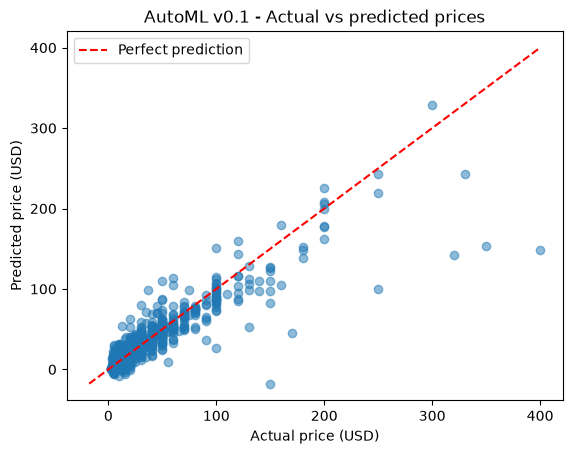

In [ ]:
# Actual vs predicted prices
plt.scatter(y_val, automl_pred, alpha=0.5)

min_price = min(y_val.min(), automl_pred.min())
max_price = max(y_val.max(), automl_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--',
    label='Perfect prediction'
)

plt.xlabel("Actual price (USD)")
plt.ylabel("Predicted price (USD)")
plt.title("AutoML v0.1 - Actual vs predicted prices")
plt.legend()
plt.show()

In [36]:
# Error analysis by price range
error_analysis = pd.DataFrame({
    'Actual_price': y_val.to_numpy(),
    'Predicted_price': automl_pred
})

error_analysis['Absolute_error'] = abs(
    error_analysis['Actual_price']
    - error_analysis['Predicted_price']
)

error_analysis['Price_range'] = pd.cut(
    error_analysis['Actual_price'],
    bins=[0, 20, 50, 100, 200, np.inf],
    labels=['0-20', '20-50', '50-100', '100-200', '200+'],
    include_lowest=True
)

price_analysis = error_analysis.groupby(
    'Price_range',
    observed=True
).agg(
    Count=('Actual_price', 'count'),
    Mean_price=('Actual_price', 'mean'),
    MAE=('Absolute_error', 'mean')
)

display(price_analysis.round(2))

,Count,Mean_price,MAE
Price_range,,,
0-20,473,12.04,5.94
20-50,263,36.47,8.57
50-100,96,77.59,13.11
100-200,36,152.21,34.50
200+,8,306.23,116.03


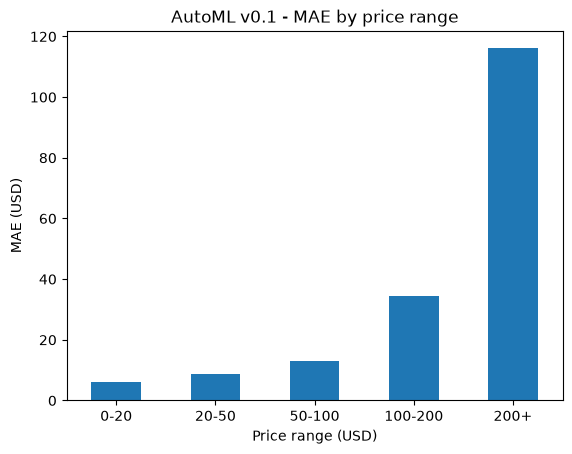

In [38]:
price_analysis['MAE'].plot(kind='bar')

plt.xlabel("Price range (USD)")
plt.ylabel("MAE (USD)")
plt.title("AutoML v0.1 - MAE by price range")
plt.xticks(rotation=0)
plt.show()

We can observe that the AutoML v0.1 pipeline slightly improves the performance of the Linear Regression model.

The MAE decreases from 9.93 to 9.70, while the RMSE decreases from 20.36 to 20.04. The R² score also increases from 0.776 to 0.783.

However, these improvements remain relatively small. This suggests that the first AutoML version does not significantly improve the prediction performance compared to our initial Linear Regression model.

The actual vs predicted prices plot shows that most predictions are relatively close to the perfect prediction line, especially for cheaper LEGO sets. However, the model tends to underestimate the price of some expensive sets. The errors become more important as the actual price increases.

The MAE by price range confirms this observation. For sets priced below $20, the MAE is 5.94 USD, while it increases to 8.57 USD for sets between $20 and $50, and to 13.11 USD for sets between $50 and $100. For sets priced between $100 and $200, the MAE reaches 34.50 USD. Finally, for sets priced above $200, the MAE is 116.03 USD.

This last result must be interpreted carefully, as only 8 sets are included in the $200+ price range, compared to 473 sets in the $0–20 range. The model therefore seems to perform better on cheaper LEGO sets, which represent the majority of the dataset, than on more expensive sets.

The AutoML pipeline is also limited by the small number of models and hyperparameters tested. We only considered Linear Regression, Ridge Regression and Decision Tree, with a limited search space.


## Improvement from the baseline

### AutoML v0.2

In this new version, we will add 4 new models, bringing the total to 7.
The 4 new models are: 
- Polynomial regression
- Lasso
- KNN regressor
- SVR
In addition, we are adding the 50% parameter to feature selection, expanding on grid search, analyzing overfitting, and, in addition to f_regression, using mutual_info_regression.

In [41]:
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import PolynomialFeatures
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import ParameterGrid
from scipy.sparse import issparse

import time

# Mutual information for numerical and categorical features
def mutual_info_score(X, y):

    if issparse(X):
        X = X.toarray()

    discrete_mask = np.zeros(X.shape[1], dtype=bool)
    discrete_mask[len(numeric_features):] = True

    return mutual_info_regression(
        X,
        y,
        discrete_features=discrete_mask,
        random_state=42
    )

In [42]:
# Polynomial preprocessing for numerical features
polynomial_numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('polynomial', PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ('scaler', StandardScaler())
])

polynomial_preprocessor = clone(preprocessor)

polynomial_preprocessor.set_params(
    num=polynomial_numeric_pipeline
)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [43]:
# AutoML v0.2 pipeline
automl_pipeline_v2 = Pipeline([
    ('preprocessing', clone(preprocessor)),
    ('feature_selection', SelectPercentile()),
    ('regressor', LinearRegression())
])

# Feature selection configurations
feature_grid_v2 = {
    'feature_selection__score_func': [
        f_regression,
        mutual_info_score
    ],
    'feature_selection__percentile': [50, 75, 100]
}

In [44]:
param_grid_v2 = [

    # Linear Regression
    {
        **feature_grid_v2,
        'regressor': [LinearRegression()]
    },

    # Ridge Regression
    {
        **feature_grid_v2,
        'regressor': [Ridge(solver='lsqr')],
        'regressor__alpha': [0.01, 0.1, 1, 10, 100]
    },

    # Lasso Regression
    {
        **feature_grid_v2,
        'regressor': [Lasso(max_iter=10000)],
        'regressor__alpha': [0.01, 0.1, 1]
    },

    # Polynomial Regression
    {
        'preprocessing': [polynomial_preprocessor],
        'preprocessing__num__polynomial__degree': [2, 3],
        'feature_selection__score_func': [f_regression],
        'feature_selection__percentile': [75, 100],
        'regressor': [LinearRegression()]
    },

    # Decision Tree Regression
    {
        **feature_grid_v2,
        'regressor': [
            DecisionTreeRegressor(random_state=42)
        ],
        'regressor__max_depth': [5, 10, 15, None],
        'regressor__min_samples_leaf': [1, 5, 10]
    },

    # K-Nearest Neighbors Regression
    {
        **feature_grid_v2,
        'regressor': [KNeighborsRegressor()],
        'regressor__n_neighbors': [3, 5, 10, 20],
        'regressor__weights': ['uniform', 'distance']
    },

    # Support Vector Regression
    {
        **feature_grid_v2,
        'regressor': [SVR()],
        'regressor__kernel': ['linear', 'rbf'],
        'regressor__C': [1, 10, 100],
        'regressor__epsilon': [0.1, 1]
    }
]

In [45]:
# Number of configurations
n_configurations_v2 = len(ParameterGrid(param_grid_v2))

print("Number of configurations:", n_configurations_v2)
print("Number of CV fits:", n_configurations_v2 * 5)

# Automated model and hyperparameter selection
automl_v2 = GridSearchCV(
    estimator=automl_pipeline_v2,
    param_grid=param_grid_v2,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score='raise',
    return_train_score=True,
    verbose=1
)

# Training
start_time = time.time()

automl_v2.fit(X_train, y_train)

training_time_v2 = time.time() - start_time

# Best configuration
best_automl_model_v2 = automl_v2.best_estimator_

print("\nBest parameters:")
print(automl_v2.best_params_)

print("\nBest CV RMSE:", -automl_v2.best_score_)

print(
    "Total training time:",
    round(training_time_v2, 2),
    "seconds"
)

Number of configurations: 250
Number of CV fits: 1250
Fitting 5 folds for each of 250 candidates, totalling 1250 fits

Best parameters:
{'feature_selection__percentile': 75, 'feature_selection__score_func': <function f_regression at 0x00000225143D60C0>, 'preprocessing': ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('polynomial',
                                                  PolynomialFeatures(include_bias=False)),
                                                 ('scaler', StandardScaler())]),
                                 ['Year', 'Num_Instructions', 'Pieces', 'Owned',
                                  'Rating', 'Total_Quantity']),
                                ('cat',
                                 Pipeline(steps=[('encoder',
                                                  OneHotEncod

## Protocol evaluation

# References  
- Brown University, LEGO Price Prediction, project report.  
    https://cs.brown.edu/media/filer_public/ba/7b/ba7b4638-d162-44b3-a302-81a46ef9a78d/tangeric_capstone_abstract.pdf?utm_source=chatgpt.com
- Peterson & Ziegler (2021), Building a Multiple Linear Regression Model With LEGO Brick Data.  
    https://www.tandfonline.com/doi/pdf/10.1080/26939169.2021.1946450?utm_source=chatgpt.com